# Chapter 1. YOLO26 소개

## 1.1 YOLO란 무엇인가?

**YOLO**는 **You Only Look Once**의 약자입니다.

일반적인 객체 탐지 알고리즘은 이미지를 여러 번 분석하지만, YOLO는 이미지를 **딱 한 번만 보고(Only Look Once)** 모든 객체를 동시에 탐지합니다. 그래서 매우 빠릅니다.

```
일반 탐지: 이미지 → 후보 영역 추출 → 각 영역 분류 → 결과 (느림)
YOLO:     이미지 → 단 한 번에 모든 객체 탐지 → 결과 (빠름)
```

## 1.2 환경 확인

실습 전에 설치 환경을 확인해봅시다.

In [1]:
# ultralytics 버전 확인
import ultralytics
print("ultralytics 버전:", ultralytics.__version__)

ultralytics 버전: 8.4.192


In [2]:
%matplotlib inline

In [3]:
# 사용 가능한 YOLO26 모델 구성 파일 목록 확인
import os
import glob
import ultralytics

pkg_path = os.path.dirname(ultralytics.__file__)
models = glob.glob(f"{pkg_path}/cfg/models/26/yolo26*.yaml")

print("사용 가능한 YOLO26 모델 구성 파일:")
for model in sorted(models):
    print(f"  - {os.path.basename(model)}")

사용 가능한 YOLO26 모델 구성 파일:
  - yolo26-cls.yaml
  - yolo26-depth.yaml
  - yolo26-obb.yaml
  - yolo26-p2.yaml
  - yolo26-p6.yaml
  - yolo26-pose.yaml
  - yolo26-seg.yaml
  - yolo26-sem.yaml
  - yolo26.yaml


In [4]:
# GPU 사용 가능 여부 확인
import torch

if torch.cuda.is_available():
    print(f"GPU 사용 가능: {torch.cuda.get_device_name(0)}")
    print(f"GPU 메모리: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("GPU 없음 - CPU로 실행됩니다 (속도가 느릴 수 있습니다)")

GPU 사용 가능: NVIDIA GeForce RTX 5060 Ti
GPU 메모리: 15.9 GB


In [5]:
# 샘플 이미지 경로 확인
import os
from ultralytics.utils import ASSETS

print("샘플 이미지 경로:", ASSETS)
print("사용 가능한 이미지:")
for f in os.listdir(ASSETS):
    print(f"  - {f}")

샘플 이미지 경로: C:\Users\SSAFY\Desktop\261030-yolo-26\books\venv\Lib\site-packages\ultralytics\assets
사용 가능한 이미지:
  - bus.jpg
  - zidane.jpg


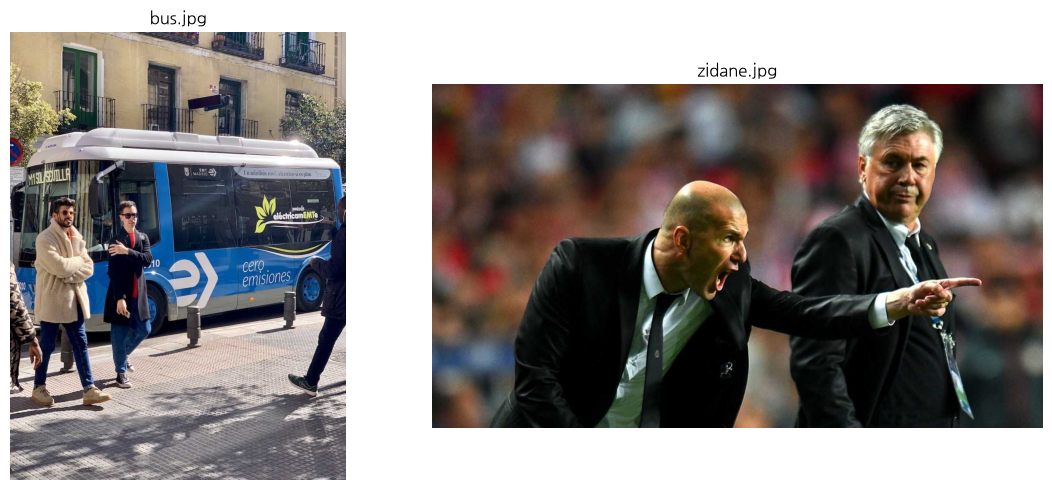

In [6]:
# 샘플 이미지 미리보기 (bus.jpg, zidane.jpg)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import koreanize_matplotlib
from ultralytics.utils import ASSETS

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, ["bus.jpg", "zidane.jpg"]):
    img = mpimg.imread(str(ASSETS / name))
    ax.imshow(img)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 1.3 정리

- YOLO는 이미지를 **한 번만 보고** 객체를 탐지하는 빠른 알고리즘입니다
- 다음 챕터에서 가장 기본 태스크인 **Object Detection**을 실습합니다
